# Matching and observational causal inference: a practical textbook

A loyalty programme was offered to customers without randomisation. More engaged
customers were more likely to receive it, so the treated and control groups differ
before we measure any outcome.

This chapter develops the causal logic first and the HypEx configuration second.
The synthetic data contain a known additive effect of **12**, which lets us compare
each estimate with the truth.

## Learning objectives

- define ATE, ATT and ATC with potential outcomes;
- decompose naive association into a causal effect and selection bias;
- state consistency, conditional exchangeability and overlap in usable language;
- understand Mahalanobis matching, bias correction and 1:k matching;
- evaluate matched balance and segment-specific effects without relying only on
  p-values.

## Chapter map and notation

1. Potential outcomes and identification.
2. Confounding in the generated data.
3. Mahalanobis matching and effect estimates.
4. Balance, overlap and robustness.
5. Grouped matching and limitations.

For each customer, $Y_i(1)$ is the outcome with the programme and $Y_i(0)$
is the outcome without it. Only one is observed. $D_i=1$ denotes treatment,
$X_i$ denotes pre-treatment covariates, and $\tau$ denotes a causal effect.

> **Central warning.** Matching is a design method, not a statistical
> ritual. If a important cause of both $D$ and $Y$ is absent from $X$,
> elegant distances and small p-values cannot recover identification.

## 1. The problem is confounding, not just unequal sample sizes

For covariates $X$, treatment $D$ and outcome $Y$, our generating process is

$$X \rightarrow D,\qquad X \rightarrow Y,\qquad D \rightarrow Y.$$

Identification relies on **conditional exchangeability**,
$Y(d) \perp D \mid X$, and **overlap**: every treated customer must have a
plausible control counterpart. Matching addresses observed $X$; it cannot
remove confounding from variables we failed to measure.

### ATE, ATT and ATC are different averages

The individual effect is $Y_i(1)-Y_i(0)$, but it is never observed for the
same customer at the same time. We therefore define population averages:

$$\operatorname{ATE}=\mathbb E[Y(1)-Y(0)],$$

$$\operatorname{ATT}=\mathbb E[Y(1)-Y(0)\mid D=1],$$

$$\operatorname{ATC}=\mathbb E[Y(1)-Y(0)\mid D=0].$$

They coincide under a constant effect or appropriate effect homogeneity,
but not generally. If high-engagement customers both select treatment more
often and respond more strongly, ATT will exceed ATC.

The naive treated-minus-control contrast decomposes as

$$\mathbb E[Y\mid D=1]-\mathbb E[Y\mid D=0]
=\operatorname{ATT}+
\left(\mathbb E[Y(0)\mid D=1]-\mathbb E[Y(0)\mid D=0]\right).$$

The last line is **selection bias**: the difference in untreated outcomes
between the kinds of customers who do and do not select treatment.

### The three assumptions behind the matching estimate

1. **Consistency:** $Y=DY(1)+(1-D)Y(0)$; the treatment actually received
   defines the observed potential outcome.
2. **Conditional exchangeability:** $\{Y(0),Y(1)\}\perp D\mid X$. Within
   comparable covariate profiles, treatment is as good as random with
   respect to potential outcomes.
3. **Positivity / overlap:** $0<P(D=1\mid X=x)<1$ where we want an effect.
   Each such profile needs a plausible counterpart.

SUTVA adds no interference and no hidden treatment versions. None of these
assumptions is proven by a balance table.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hypex import Matching
from hypex.dataset import (
    Dataset,
    FeatureRole,
    GroupingRole,
    InfoRole,
    TargetRole,
    TreatmentRole,
)

# Assignment depends on observed X, and X also enters the outcome.
rng = np.random.default_rng(11)
n_users = 1_200
age = rng.normal(40, 10, n_users)
income = rng.normal(60, 15, n_users)
pre_spend = 20 + 0.5 * age + 0.8 * income + rng.normal(0, 15, n_users)
channel = rng.choice(["app", "web"], n_users)
propensity_logit = (
    -2
    + 0.04 * (age - 40)
    + 0.05 * (income - 60)
    + 0.03 * (pre_spend - 80)
    + 0.4 * (channel == "app")
)
propensity = 1 / (1 + np.exp(-propensity_logit))
treat = rng.binomial(1, propensity)
outcome = (
    10
    + 0.4 * age
    + 0.7 * income
    + 1.1 * pre_spend
    + 12 * treat
    + rng.normal(0, 15, n_users)
)
matching_df = pd.DataFrame(
    {
        "user_id": np.arange(n_users),
        "treat": treat,
        "age": age,
        "income": income,
        "pre_spend": pre_spend,
        "channel": channel,
        "outcome": outcome,
    }
)
matching_df.head()

/Users/danilsamsutdinov/HypEx/.venv/lib/python3.11/site-packages/pyspark/pandas/__init__.py:50: UserWarning: 'PYARROW_IGNORE_TIMEZONE' environment variable was not set. It is required to set this environment variable to '1' in both driver and executor sides if you use pyarrow>=2.0.0. pandas-on-Spark will set it for you but it does not work if there is a Spark context already launched.
  warnings.warn(


,user_id,treat,age,income,pre_spend,channel,outcome
0,0,0,40.341928,44.283612,94.407372,app,181.443741
1,1,0,53.597475,42.664182,85.564922,app,163.225243
2,2,0,52.247211,56.499392,76.866225,web,130.562948
3,3,0,34.896929,43.679513,87.442121,app,150.946801
4,4,1,37.020305,96.829027,113.278793,app,212.567572


In [2]:
naive_effect = (
    matching_df.loc[matching_df.treat == 1, "outcome"].mean()
    - matching_df.loc[matching_df.treat == 0, "outcome"].mean()
)
pd.DataFrame(
    {
        "treatment share": [matching_df.treat.mean()],
        "naive difference": [naive_effect],
        "true additive effect": [12.0],
    }
).round(3)

,treatment share,naive difference,true additive effect
0,0.237,43.657,12.0


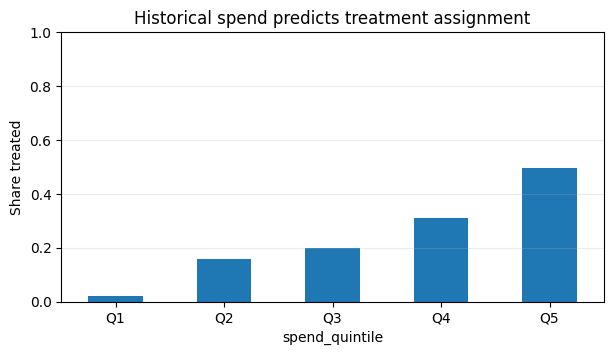

In [3]:
treatment_by_history = (
    matching_df.assign(
        spend_quintile=pd.qcut(
            matching_df.pre_spend, 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
        )
    )
    .groupby("spend_quintile", observed=True)
    .agg(treatment_rate=("treat", "mean"), customers=("treat", "size"))
)
ax = treatment_by_history.treatment_rate.plot(
    kind="bar", figsize=(7, 3.5), ylim=(0, 1), rot=0
)
ax.set_ylabel("Share treated")
ax.set_title("Historical spend predicts treatment assignment")
ax.grid(axis="y", alpha=0.25)
plt.show()

### Read the assignment plot before the outcome

The increasing treatment rate across historical-spend quintiles is direct
evidence of selection on observed covariates. It does not by itself prove
confounding: spend must also be related to the potential outcome. In this
generator it explicitly enters $Y(0)$, so both arrows are present.

This plot also previews overlap. If the highest quintile contained only
treated users, there would be no data-driven control counterpart there.
Trimming or changing the target population would be safer than extrapolating.

## 2. Declare covariates separately from the outcome

Only pre-treatment variables receive `FeatureRole`. `outcome` remains a
target and is never part of the distance. `channel` is categorical; the
matching pipeline one-hot encodes it into additional fields while retaining
the original column for the chi-square quality check.

In [4]:
roles = {
    "user_id": InfoRole(int),
    "treat": TreatmentRole(int),
    "age": FeatureRole(float),
    "income": FeatureRole(float),
    "pre_spend": FeatureRole(float),
    "channel": FeatureRole(str),
    "outcome": TargetRole(float),
}
matching_data = Dataset(roles=roles, data=matching_df)

### Why Mahalanobis distance?

Euclidean distance treats one unit of every standardised feature alike and
ignores correlation. Mahalanobis distance uses the pooled covariance
matrix $\Sigma$:

$$d_M(x_i,x_j)=\sqrt{(x_i-x_j)^T\Sigma^{-1}(x_i-x_j)}.$$

The whitening step prevents two strongly correlated features from counting
as independent evidence twice. Optional `weights` can then emphasise
substantively important covariates; unspecified features receive weight 1.

### What the matching pipeline is doing

1. One-hot encode categorical features and cast numeric features.
2. Estimate the pooled feature covariance and construct a whitening map.
3. Find nearest neighbours across treatment groups in that transformed
   space.
4. Optionally estimate residual bias from outcome regressions.
5. Contrast each outcome with its matched counterfactual and aggregate the
   pairwise effects.

If $z=Lx$ is a whitened feature vector, nearest-neighbour search can use
ordinary Euclidean distance in $z$. The corresponding distance in $x$ is
Mahalanobis distance. Feature weights alter this geometry and should encode
substantive priorities, not the desired effect size.

For one treated observation $i$ matched to control $j(i)$, the simple ATT
pair contrast is $\widehat\tau_i=Y_i-Y_{j(i)}$. The ATT estimate averages
these contrasts over treated observations. ATE additionally uses the
reverse direction and combines both sides.

In [5]:
mahalanobis_result = Matching(
    distance="mahalanobis",
    weights={"age": 1.0, "income": 1.0, "pre_spend": 2.0},
    bias_estimation=True,
    quality_tests=["t-test", "ks-test", "chi2-test"],
    extract_full_data=True,
    compute_indexes=True,
).execute(matching_data)
mahalanobis_result.summary

,Effect Size,Standard Error,P-value,CI Lower,CI Upper
ATT,11.9276,2.2833,0.0000,7.4524,16.4028
ATC,8.6787,2.9045,0.0028,2.9858,14.3715
ATE,9.4476,2.4653,0.0001,4.6155,14.2796


### Read the effect table row by row

`Effect Size` is the estimated mean treatment effect in outcome units.
`Standard Error` describes estimator uncertainty, not the standard
deviation of individual outcomes. Under the usual normal approximation,
the interval is

$$\widehat\tau\pm z_{1-\alpha/2}\widehat{\operatorname{se}}(\widehat\tau).$$

The ATT row answers whether the programme worked for customers who actually
received it. The ATC row is the counterfactual effect on those who did not.
ATE targets both populations together. Choose the row from the product
question before comparing their p-values.

Reuse of a control as several neighbours creates dependence. Treating every
pair as a new independent observation would understate uncertainty, which
is why match-reuse information belongs in the variance calculation.

The shell currently reports all three estimands:

- **ATT**: average effect on treated customers;
- **ATC**: average effect on control customers;
- **ATE**: average effect over both sides.

They need not coincide when effects are heterogeneous. The confidence
intervals account for repeated use of controls as neighbours; repeated
matches must not be treated as independent new observations.

In [6]:
mahalanobis_result.quality_results

,feature,group,TTest pass,TTest p-value,KSTest pass,KSTest p-value,Chi2Test pass,Chi2Test p-value
0,age,0,OK,0.147863,NOT OK,0.002598,NaN,NaN
1,age,1,OK,0.382868,OK,0.759210,NaN,NaN
2,income,0,NOT OK,0.002213,NOT OK,0.000084,NaN,NaN
3,income,1,OK,0.192953,OK,0.309761,NaN,NaN
4,pre_spend,0,NOT OK,0.005015,NOT OK,0.000005,NaN,NaN
5,pre_spend,1,OK,0.323472,OK,0.619195,NaN,NaN
6,channel,0,NaN,NaN,NaN,NaN,OK,0.074383
7,channel,1,NaN,NaN,NaN,NaN,NOT OK,0.000494


### Measure ATT balance in outcome-relevant units

Below we compute SMD before matching and among treated customers with a
valid matched control. The post-matching SMD applies the same formula to
treated customers and their matched controls.

A negative value means the matched control has a lower covariate mean.
We are looking for movement toward zero, especially for `pre_spend`, which
strongly predicts both selection and outcome.

,before,after ATT matching
age,0.525,0.073
income,0.935,0.109
pre_spend,1.026,0.083


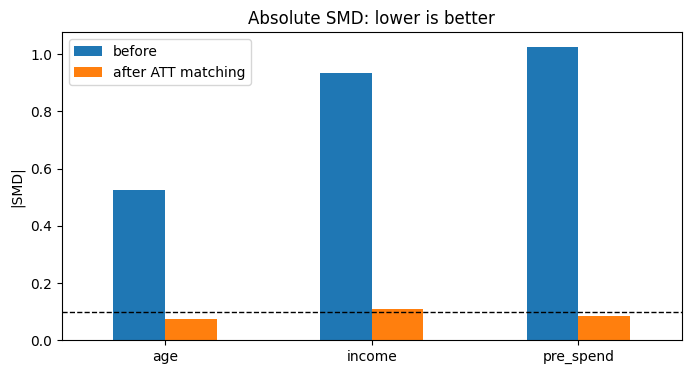

In [7]:
# ATT diagnostic: treated rows and their first matched control.
matched_wide = mahalanobis_result.full_data.raw_data


def att_smd(feature, matched=False):
    if not matched:
        control = matching_df.loc[matching_df.treat == 0, feature]
        treated = matching_df.loc[matching_df.treat == 1, feature]
    else:
        matched_column = f"{feature}_matched_0"
        pairs = matched_wide.loc[
            (matched_wide.treat == 1) & matched_wide[matched_column].notna()
        ]
        control = pairs[matched_column]
        treated = pairs[feature]
    pooled_sd = np.sqrt((control.var() + treated.var()) / 2)
    return (treated.mean() - control.mean()) / pooled_sd


balance = pd.DataFrame(
    {
        "before": {
            feature: att_smd(feature) for feature in ["age", "income", "pre_spend"]
        },
        "after ATT matching": {
            feature: att_smd(feature, matched=True)
            for feature in ["age", "income", "pre_spend"]
        },
    }
)
display(balance.round(3))
balance.abs().plot.bar(
    figsize=(8, 4),
    title="Absolute SMD: lower is better",
    ylabel="|SMD|",
    rot=0,
)
plt.axhline(0.1, color="black", linestyle="--", linewidth=1)
plt.show()

The 0.1 line is only a screening reference. A covariate can have a small
mean difference and a very different tail, so inspect distributions and
extreme values too. Conversely, a residual SMD above 0.1 on an irrelevant
variable need not be more worrying than imbalance on a strong prognostic one.

Quality tests compare matched pairs on the original covariates. As in A/A,
`OK` means no detected difference. Do not optimise matching until every
p-value exceeds 0.05: p-values depend on sample size and are not balance
metrics. Also inspect standardised mean differences, overlap plots and the
number of unmatched or repeatedly reused observations in a real analysis.

## 3. Separate the design choices

We now compare three estimates: raw L2 matching, Mahalanobis without bias
correction, and the Mahalanobis bias-corrected result above. Bias correction
fits an outcome regression and adjusts for residual covariate imbalance
within matched pairs; it is not a replacement for poor overlap.

In [8]:
l2_result = Matching(
    distance="l2",
    bias_estimation=False,
    quality_tests=["t-test"],
).execute(matching_data)
unadjusted_result = Matching(
    distance="mahalanobis",
    weights={"age": 1.0, "income": 1.0, "pre_spend": 2.0},
    bias_estimation=False,
    quality_tests=["t-test"],
).execute(matching_data)

In [9]:
def get_estimand(output, estimand="ATE"):
    row = output.summary.raw_data.loc[estimand]
    return {
        "effect": row["Effect Size"],
        "CI lower": row["CI Lower"],
        "CI upper": row["CI Upper"],
    }


effect_comparison = pd.DataFrame(
    {
        "naive": {"effect": naive_effect, "CI lower": np.nan, "CI upper": np.nan},
        "L2": get_estimand(l2_result),
        "Mahalanobis": get_estimand(unadjusted_result),
        "Mahalanobis + bias correction": get_estimand(mahalanobis_result),
    }
).T
effect_comparison["CI width"] = (
    effect_comparison["CI upper"] - effect_comparison["CI lower"]
)
effect_comparison.round(3)

,effect,CI lower,CI upper,CI width
naive,43.657,NaN,NaN,NaN
L2,12.030,6.824,17.234,10.410
Mahalanobis,13.562,8.499,18.626,10.127
Mahalanobis + bias correction,9.448,4.616,14.280,9.664


### Bias correction: what is subtracted

Let $\widehat\mu_0(x)$ be an outcome regression for untreated outcomes. A
bias-corrected treated-control pair contrast has the form

$$\widehat\tau_i=
\left(Y_i-Y_{j(i)}\right)
-\left(\widehat\mu_0(X_i)-\widehat\mu_0(X_{j(i)})\right).$$

The second term estimates the residual untreated-outcome difference caused
by imperfect covariate matching. Similar logic applies in the reverse
direction with $\widehat\mu_1$.

This is an Abadie–Imbens-style adjustment. It can reduce residual matching
bias, but its outcome model introduces another specification to check.
Severe lack of overlap is still a design failure, not a regression problem.

One synthetic run is an illustration, not a benchmark proving that one
distance is universally best. In practice, compare balance and robustness
across defensible specifications rather than selecting the estimate closest
to the answer you want.

## 4. Inspect the actual matched pairs

`compute_indexes=True` enables index extraction, while
`extract_full_data=True` builds the wide original-versus-neighbour table.
The wide table can be expensive, so both are opt-in; in this version the
wide extraction is also needed to materialise `indexes`.

In [10]:
display(mahalanobis_result.indexes.raw_data.head())
pair_columns = [
    "user_id",
    "treat",
    "age",
    "age_matched_0",
    "pre_spend",
    "pre_spend_matched_0",
    "outcome",
    "outcome_matched_0",
]
mahalanobis_result.full_data.raw_data[pair_columns].head()

,indexes_0
0,373
1,256
2,1033
3,650
4,960


,user_id,treat,age,age_matched_0,pre_spend,pre_spend_matched_0,outcome,outcome_matched_0
0,0,0,40.341928,39.863930,94.407372,93.742540,181.443741,198.364699
1,1,0,53.597475,48.036656,85.564922,82.350601,163.225243,170.565164
2,2,0,52.247211,55.331289,76.866225,80.806486,130.562948,187.541081
3,3,0,34.896929,38.857635,87.442121,81.412179,150.946801,142.804863
4,4,1,37.020305,32.573422,113.278793,112.681162,212.567572,223.593330


### Diagnose overlap with a propensity score

A propensity score is $e(x)=P(D=1\mid X=x)$. It is not required for
Mahalanobis matching, but its distributions offer a compact overlap
diagnostic. We fit a transparent logistic model using numeric
pre-treatment features only.

Regions with almost no mass from one arm are regions where any matched
estimate relies on distant neighbours or extrapolation. Do not interpret
this fitted model as proof of conditional exchangeability.

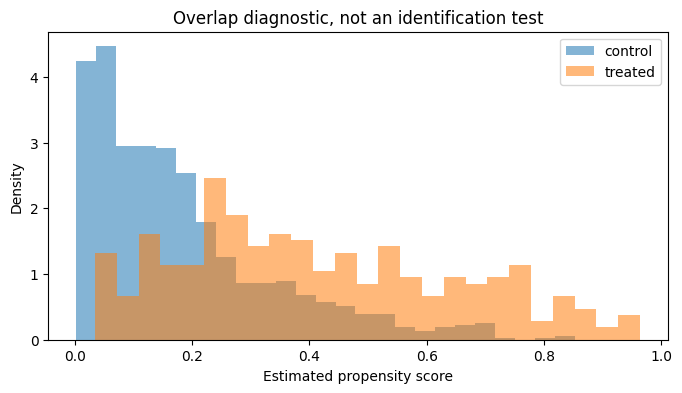

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

propensity_features = ["age", "income", "pre_spend"]
propensity_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=11, max_iter=1_000),
)
propensity_model.fit(matching_df[propensity_features], matching_df.treat)
estimated_propensity = propensity_model.predict_proba(matching_df[propensity_features])[
    :, 1
]

fig, ax = plt.subplots(figsize=(8, 4))
for group, label in [(0, "control"), (1, "treated")]:
    ax.hist(
        estimated_propensity[matching_df.treat.to_numpy() == group],
        bins=25,
        alpha=0.55,
        density=True,
        label=label,
    )
ax.set_xlabel("Estimated propensity score")
ax.set_ylabel("Density")
ax.set_title("Overlap diagnostic, not an identification test")
ax.legend()
plt.show()

### More than one neighbour

`n_neighbors=3` averages several counterparts. This can reduce matching
variance but may increase bias if the second and third neighbours are much
farther away. HypEx's quality tests use the first neighbour column; use
additional balance diagnostics when comparing neighbour counts.

In [12]:
three_neighbours = Matching(
    distance="mahalanobis",
    n_neighbors=3,
    quality_tests=[],
).execute(matching_data)
three_neighbours.summary

,Effect Size,Standard Error,P-value,CI Lower,CI Upper
ATT,12.0299,1.6212,0.0,8.8522,15.2075
ATC,10.6299,1.9170,0.0,6.8725,14.3873
ATE,10.9613,1.6931,0.0,7.6427,14.2798


### The 1:k bias–variance trade-off

More neighbours usually smooth individual pair contrasts and reduce their
variance. But neighbours 2 and 3 are, by construction, at least as distant
as neighbour 1. A useful mental model is

$$\text{total error}\approx
\text{matching bias from distant pairs}+\text{estimation variance}.$$

Increasing $k$ targets the second term and can increase the first. Compare
distances and balance across $k$; do not select it solely because its
confidence interval is narrower.

## 5. Exact matching within business segments

Sometimes an app customer should only be matched with an app customer.
Move `channel` to `GroupingRole` and set `group_match=True`: HypEx runs the
whole matching pipeline independently in each group and prefixes the result
columns by segment.

In [13]:
grouped_roles = dict(roles)
grouped_roles["channel"] = GroupingRole(str)
grouped_result = Matching(
    group_match=True,
    distance="mahalanobis",
    quality_tests=["t-test"],
).execute(Dataset(roles=grouped_roles, data=matching_df))
grouped_result.summary

,app Effect Size,app Standard Error,app P-value,app CI Lower,app CI Upper,web Effect Size,web Standard Error,web P-value,web CI Lower,web CI Upper
ATC,11.6089,4.3342,0.0074,3.1139,20.1039,8.8741,3.2193,0.0058,2.5642,15.1840
ATE,12.0963,3.6601,0.0009,4.9226,19.2700,9.1018,2.8642,0.0015,3.4881,14.7156
ATT,13.4838,3.5778,0.0002,6.4713,20.4964,9.9329,2.9978,0.0009,4.0572,15.8085


### Combine segment effects explicitly

Grouped matching estimates $\widehat\tau_g$ separately in segment $g$.
If the target is the pooled ATE, a standard aggregation uses population
shares $w_g=N_g/N$:

$$\widehat\tau_{\text{pooled}}=\sum_g w_g\widehat\tau_g.$$

This is a estimand choice, not an optional formatting detail. Matching
within segments also changes the comparison set and can improve exact
balance at the cost of smaller samples.

In [14]:
# The grouped columns and population shares are both sorted app, web.
segment_effects = grouped_result.summary.raw_data.filter(like="Effect Size").loc["ATE"]
segment_weights = matching_df.channel.value_counts(normalize=True).sort_index()
pooled_effect = float(np.dot(segment_effects.to_numpy(), segment_weights.to_numpy()))
pooled_summary = pd.DataFrame(
    {
        "segment": [*list(segment_effects.index), "population-weighted ATE"],
        "effect": [*list(segment_effects.to_numpy()), pooled_effect],
    }
)
pooled_summary.round(3)

,segment,effect
0,app Effect Size,12.096
1,web Effect Size,9.102
2,population-weighted ATE,10.542


Segment-specific estimates answer a different question from one pooled ATE.
Check that each segment has enough treated and control observations and
predeclare how they should be combined.

## What matching cannot fix

- **Unobserved confounding.** A great balance table only covers measured X.
- **No overlap.** Do not extrapolate to customers with no credible match.
- **Post-treatment covariates.** Matching on them can block or create causal
  paths.
- **Too many noisy features.** Distances become less informative in high
  dimensions; prioritise prognostic pre-treatment covariates.

**Next:** [Compose custom pipelines](04_Custom_Pipelines.ipynb).

## A practical sensitivity mindset

A credible observational analysis usually includes more than one defensible
specification: alternative covariate sets, distance metrics, neighbour
counts and target populations. Agreement supports robustness; disagreement
identifies assumptions that deserve attention.

For unobserved confounding, ask how strong a hidden variable would need to
be in its relationships with both treatment and outcome to explain away the
estimate. This sensitivity question cannot be answered by adding more
post-treatment features.

### Reporting checklist

- [ ] The target estimand and population are stated before the estimate.
- [ ] Every matching covariate is pre-treatment.
- [ ] Assignment and overlap plots accompany the effect table.
- [ ] Balance includes magnitudes and distributions, not only p-values.
- [ ] Neighbour reuse, unmatched rows and distant matches are inspected.
- [ ] Grouped effects have an explicit aggregation rule.
- [ ] Unmeasured confounding is discussed as an assumption, not hidden in a
  footnote.